# VigiLense: Weapon detection (gun, knife) with YOLO26

**Dataset:** *Dangerous Items Dataset for 5-Class Object Detection* (Omiotek, 2025, Zenodo, CC BY 4.0) —
8,478 images, classes machete, knife, baseball bat, rifle, gun, YOLO labels.
This notebook downloads it **directly from Zenodo into Colab** (nothing to upload from your laptop) and
remaps it to the two VigiLense classes:

| VigiLense class | from dataset classes |
|---|---|
| 0 `gun` | gun, rifle |
| 1 `knife` | knife, machete |
| (dropped) | baseball bat |

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Run the cells top to bottom.
Keep `QUICK_TEST = True` the first time (about 5 minutes), then set it to `False` for the real run.

Cite in your report: Z. Omiotek, *Electronics* 14(17), 3540, 2025, doi:10.3390/electronics14173540; dataset doi:10.5281/zenodo.16422779.

In [ ]:
# 1) GPU check + install + connect Google Drive
!nvidia-smi
!pip install -U -q ultralytics

from google.colab import drive
drive.mount('/content/drive')

Tue Oct 20 15:52:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# 2) Settings
from pathlib import Path

DRIVE_ROOT = "/content/drive/MyDrive/vigilense"
ZIP_URL    = "https://zenodo.org/records/16422779/files/Dangerous%20Items.zip?download=1"
ZIP_MD5    = "f567c3b6e070b2c36578a09c5c7eb9e2"
DRIVE_ZIP  = Path(f"{DRIVE_ROOT}/datasets/dangerous_items.zip")   # cached copy, so you only download once
LOCAL_ZIP  = Path("/content/dangerous_items.zip")
RAW_DIR    = Path("/content/dangerous_items")
OUT_DIR    = Path("/content/weapons_yolo")

QUICK_TEST = False         # True = 3-epoch test on 10% of the data. Set False for the real training.
EPOCHS     = 3 if QUICK_TEST else 80
RUN_NAME   = "weapons_quick" if QUICK_TEST else "weapons_v1"

DRIVE_ZIP.parent.mkdir(parents=True, exist_ok=True)
print("QUICK_TEST =", QUICK_TEST, "| epochs =", EPOCHS, "| run =", RUN_NAME)

QUICK_TEST = False | epochs = 80 | run = weapons_v1


In [ ]:
# 3) Download (or reuse the Drive copy), verify, unzip
import hashlib, shutil, subprocess, os

def md5(path, chunk=1 << 22):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

if DRIVE_ZIP.exists() and DRIVE_ZIP.stat().st_size > 1_000_000_000:
    print("Using cached zip from Drive...")
    shutil.copy(DRIVE_ZIP, LOCAL_ZIP)
elif not LOCAL_ZIP.exists():
    print("Downloading from Zenodo (1.4 GB, a few minutes)...")
    subprocess.run(["curl", "-L", "--fail", "-o", str(LOCAL_ZIP), ZIP_URL], check=True)

print("Size:", round(LOCAL_ZIP.stat().st_size / 1e9, 2), "GB")
digest = md5(LOCAL_ZIP)
assert digest == ZIP_MD5, f"Checksum mismatch ({digest}). The download is incomplete: delete {LOCAL_ZIP} and rerun."
print("Checksum OK")

if not DRIVE_ZIP.exists():
    shutil.copy(LOCAL_ZIP, DRIVE_ZIP)
    print("Saved a copy to Drive:", DRIVE_ZIP)

if RAW_DIR.exists():
    shutil.rmtree(RAW_DIR)
r = subprocess.run(["unzip", "-q", str(LOCAL_ZIP), "-d", str(RAW_DIR)], capture_output=True, text=True)
print(r.stderr[-500:])
n = sum(1 for p in RAW_DIR.rglob("*") if p.is_file())
assert n > 10000, f"Unzip looks incomplete: {n} files"
print("Unzipped files:", n)

Using cached zip from Drive...
Size: 1.41 GB
Checksum OK

Unzipped files: 16956


In [ ]:
# 4) Inspect: folder structure, class list, class counts
import yaml
from collections import Counter

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
img_dirs = sorted({p.parent for p in RAW_DIR.rglob("*") if p.suffix.lower() in IMG_EXT})
print("Image folders:")
for d in img_dirs:
    print("  ", d.relative_to(RAW_DIR), "->", sum(1 for _ in d.iterdir()), "files")

# any class list shipped with the dataset?
NAMES = None
for f in list(RAW_DIR.rglob("*.yaml")) + list(RAW_DIR.rglob("*.yml")):
    y = yaml.safe_load(f.read_text())
    if isinstance(y, dict) and "names" in y:
        n = y["names"]
        NAMES = [n[k] for k in sorted(n)] if isinstance(n, dict) else list(n)
        print("Class list from", f.relative_to(RAW_DIR), ":", NAMES)
        break
if NAMES is None:
    for f in RAW_DIR.rglob("classes.txt"):
        NAMES = [l.strip() for l in f.read_text().splitlines() if l.strip()]
        print("Class list from", f.relative_to(RAW_DIR), ":", NAMES)
        break

def swap(path, a, b):
    # replace the last path component named a with b (images <-> labels)
    parts = list(path.parts)
    i = len(parts) - 1 - parts[::-1].index(a)
    parts[i] = b
    return Path(*parts)

def label_for(img_path):
    return swap(img_path, "images", "labels").with_suffix(".txt")

label_files = [p for p in RAW_DIR.rglob("*.txt") if "labels" in p.parts]
ids = Counter()
for lf in label_files:
    for line in lf.read_text().splitlines():
        if line.strip():
            ids[int(float(line.split()[0]))] += 1
print("Label files:", len(label_files), "| boxes per class id:", dict(sorted(ids.items())))
if NAMES is None:
    print("\nNo class list found in the zip. Run the next cell and check the pictures to confirm which id is which.")

Image folders:
   Dangerous Items/images/test -> 1272 files
   Dangerous Items/images/train -> 5934 files
   Dangerous Items/images/val -> 1272 files
Label files: 8478 | boxes per class id: {0: 1793, 1: 1708, 2: 1796, 3: 1753, 4: 1755}

No class list found in the zip. Run the next cell and check the pictures to confirm which id is which.


class id 0  (dataset name: ?)


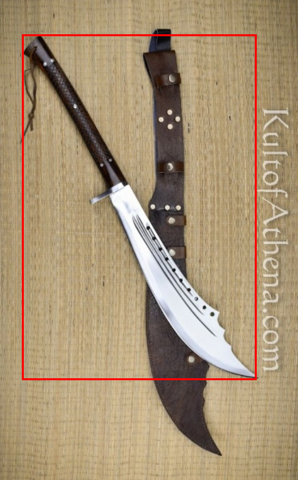

class id 1  (dataset name: ?)


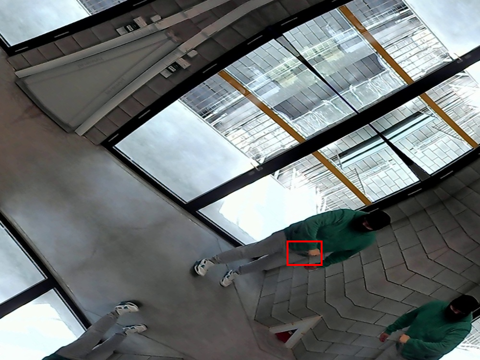

class id 2  (dataset name: ?)


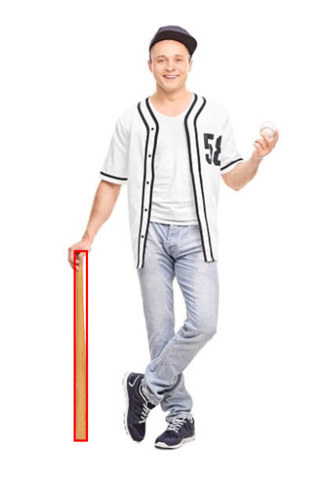

class id 3  (dataset name: ?)


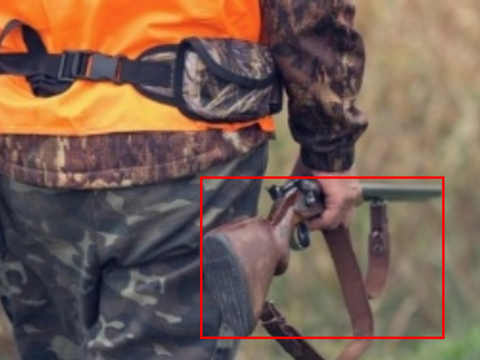

class id 4  (dataset name: ?)


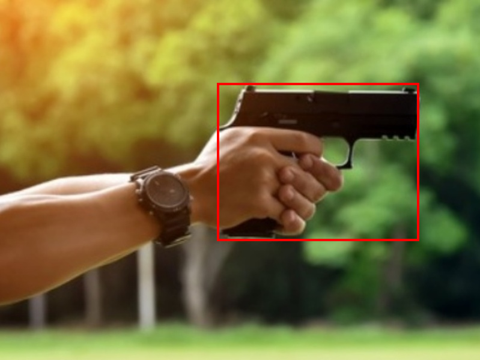

In [ ]:
# 5) Look at one example per class id (CHECK THIS before training)
import random
from PIL import Image, ImageDraw
from IPython.display import display

def image_for(label_path):
    base = swap(label_path, "labels", "images")
    for ext in IMG_EXT:
        p = base.with_suffix(ext)
        if p.exists():
            return p

random.seed(0)
for cid in sorted(ids):
    cands = [lf for lf in label_files if any(l.split()[0] == str(cid) for l in lf.read_text().splitlines() if l.strip())]
    lf = random.choice(cands)
    ip = image_for(lf)
    im = Image.open(ip).convert("RGB")
    W, H = im.size
    d = ImageDraw.Draw(im)
    for l in lf.read_text().splitlines():
        c, x, y, w, h = l.split()[:5]
        if c == str(cid):
            x, y, w, h = float(x) * W, float(y) * H, float(w) * W, float(h) * H
            d.rectangle([x - w / 2, y - h / 2, x + w / 2, y + h / 2], outline="red", width=4)
    label = NAMES[cid] if NAMES and cid < len(NAMES) else "?"
    print(f"class id {cid}  (dataset name: {label})")
    im.thumbnail((480, 480))
    display(im)

In [ ]:
# 6) Class mapping -> VigiLense classes (0 = gun, 1 = knife)
# If the zip had no class list, CHECK the pictures above and edit ID_NAMES so each id has the right name.
ID_NAMES = NAMES or ["machete", "knife", "baseball bat", "rifle", "gun"]   # order given on the Zenodo page (assumption)

TO_VIGILENSE = {"gun": 0, "rifle": 0, "pistol": 0, "handgun": 0,
                "knife": 1, "machete": 1}
REMAP = {}
for i, n in enumerate(ID_NAMES):
    key = n.lower().strip()
    REMAP[i] = TO_VIGILENSE.get(key)          # None = dropped (e.g. baseball bat)
print("Dataset id -> VigiLense id:", {f"{i} {ID_NAMES[i]}": REMAP[i] for i in REMAP})
assert 0 in REMAP.values() and 1 in REMAP.values(), "Mapping must contain both gun and knife - fix ID_NAMES."

Dataset id -> VigiLense id: {'0 machete': 1, '1 knife': 1, '2 baseball bat': None, '3 rifle': 0, '4 gun': 0}


In [ ]:
# 7) Build the remapped dataset (train / val / test) and data.yaml
def split_of(path):
    parts = [p.lower() for p in path.parts]
    if any(p in ("train", "training") for p in parts): return "train"
    if any(p in ("val", "valid", "validation") for p in parts): return "val"
    if any(p in ("test", "testing") for p in parts): return "test"
    return None

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
stats = {s: Counter() for s in ("train", "val", "test")}
unsplit = 0
for d in img_dirs:
    split = split_of(d.relative_to(RAW_DIR))
    if split is None:
        unsplit += sum(1 for _ in d.iterdir())
        continue
    (OUT_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (OUT_DIR / split / "labels").mkdir(parents=True, exist_ok=True)
    for ip in d.iterdir():
        if ip.suffix.lower() not in IMG_EXT:
            continue
        lp = label_for(ip)
        out = []
        if lp.exists():
            for l in lp.read_text().splitlines():
                if not l.strip():
                    continue
                c, *box = l.split()
                new = REMAP.get(int(float(c)))
                if new is not None:
                    out.append(" ".join([str(new)] + box[:4]))
                    stats[split][new] += 1
        shutil.copy2(ip, OUT_DIR / split / "images" / ip.name)
        (OUT_DIR / split / "labels" / (ip.stem + ".txt")).write_text("\n".join(out))
        stats[split]["images"] += 1
assert unsplit == 0, f"{unsplit} images were not in a train/val/test folder - tell me the folder names printed in cell 4."

for s in stats:
    print(f"{s:5s}: {stats[s]['images']} images | gun boxes {stats[s][0]} | knife boxes {stats[s][1]}")
assert stats["train"][0] > 0 and stats["train"][1] > 0, "No gun/knife boxes found - send me the output of cells 4 and 7."

DATA_YAML = OUT_DIR / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(OUT_DIR), "train": "train/images", "val": "val/images", "test": "test/images",
    "names": {0: "gun", 1: "knife"}}, sort_keys=False))
print(DATA_YAML.read_text())

train: 5934 images | gun boxes 2463 | knife boxes 2469
val  : 1272 images | gun boxes 521 | knife boxes 504
test : 1272 images | gun boxes 524 | knife boxes 528
path: /content/weapons_yolo
train: train/images
val: val/images
test: test/images
names:
  0: gun
  1: knife



In [ ]:
# 8) Train (checkpoints saved straight to Google Drive)
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=640,
    batch=16,
    patience=20,
    fraction=0.1 if QUICK_TEST else 1.0,
    project=f"{DRIVE_ROOT}/runs",
    name=RUN_NAME,
    exist_ok=True,
    workers=2,
    plots=True,
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/weapons_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=weapons_v1, nbs=64, nms=None, opset=None, optimize=False, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b164d9126d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [ ]:
# 9) Evaluate the best model on the TEST split (report these numbers)
BEST = f"{DRIVE_ROOT}/runs/{RUN_NAME}/weights/best.pt"
metrics = YOLO(BEST).val(data=str(DATA_YAML), split="test", imgsz=640)
print(f"mAP50: {metrics.box.map50:.3f} | mAP50-95: {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.mp:.3f} | Recall: {metrics.box.mr:.3f}")
for i, name in enumerate(["gun", "knife"]):
    p, r, ap50, ap = metrics.box.class_result(i)
    print(f"  {name:5s}  P {p:.3f}  R {r:.3f}  mAP50 {ap50:.3f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2516.9±1083.0 MB/s, size: 114.9 KB)
val: Scanning /content/weapons_yolo/test/labels.cache... 1272 images, 337 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1272/1272 410.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 80/80 5.8it/s 13.8s
                   all       1272       1052      0.916      0.831      0.903      0.625
                   gun        490        524      0.941      0.866      0.933      0.621
                 knife        497        528       0.89      0.796      0.872      0.629
Speed: 1.2ms preprocess, 3.3ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/runs/detect/val-2
mAP50: 0.903 | mAP50-95: 0.625
Precision: 0.916 | Recall: 0.831
  gun    P 0.941  R 

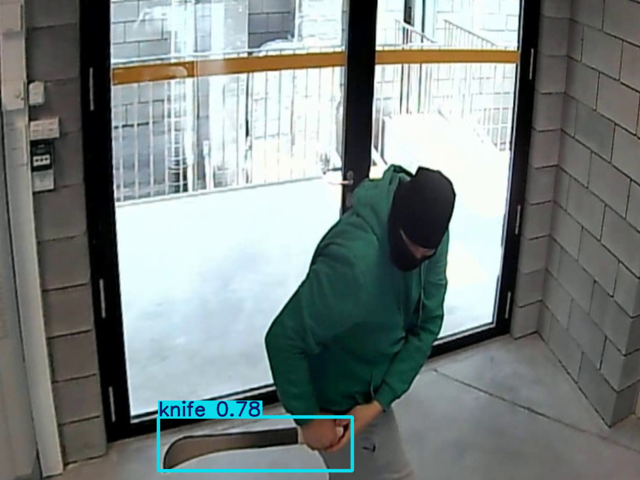

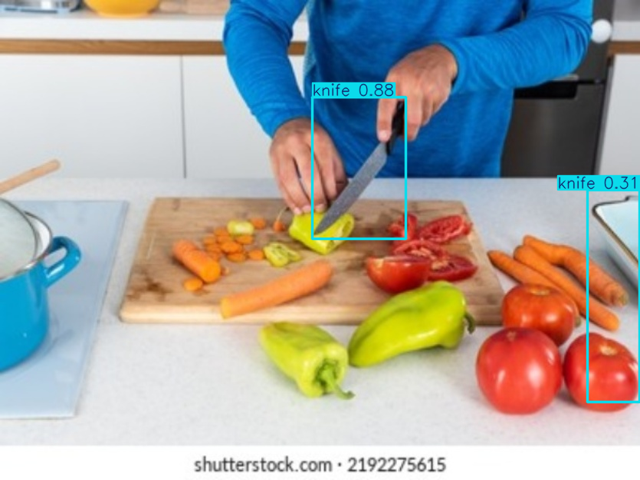

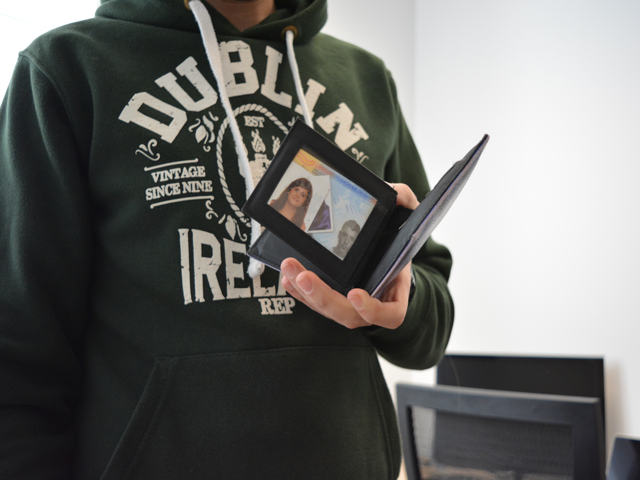

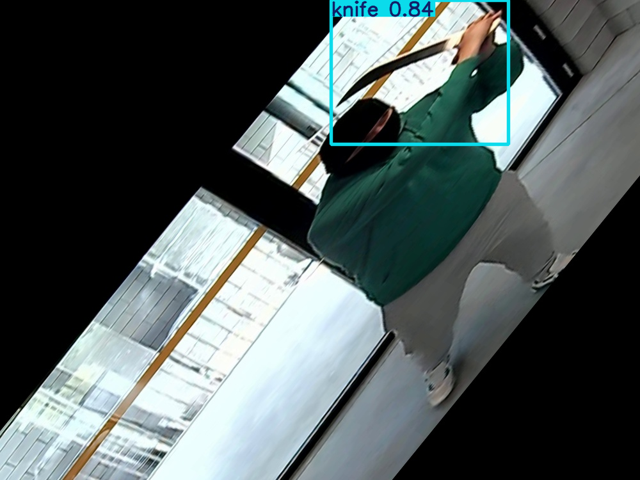

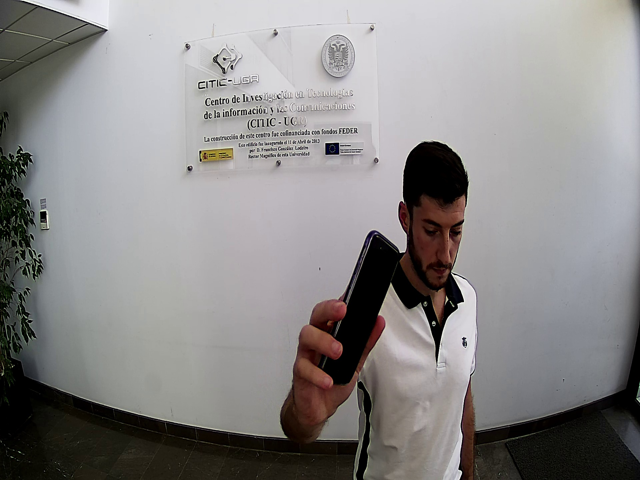

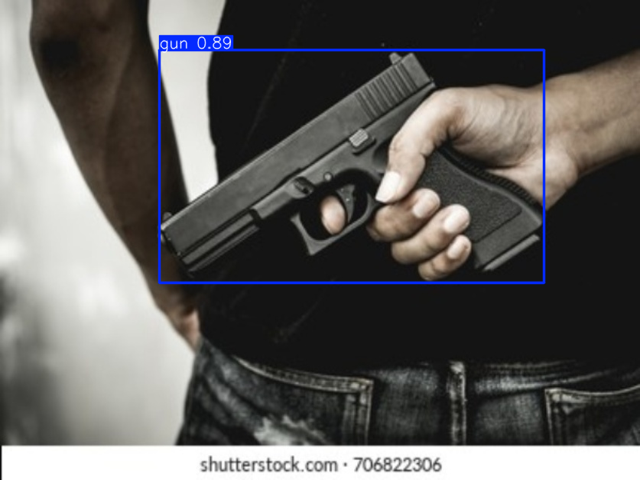

In [ ]:
# 10) Look at predictions on random test images
best_model = YOLO(BEST)
test_imgs = list((OUT_DIR / "test" / "images").iterdir())
for p in random.sample(test_imgs, 6):
    r = best_model.predict(str(p), conf=0.3, verbose=False)[0]
    display(Image.fromarray(r.plot()[..., ::-1]).resize((640, 480)))

## If Colab disconnects during training
Re-run cells 1, 2, 3, 4, 6 and 7 (the zip is cached in Drive, so no new download), then run the cell below.

In [ ]:
# Resume an interrupted training run
YOLO(f"{DRIVE_ROOT}/runs/{RUN_NAME}/weights/last.pt").train(resume=True)

WARNING ⚠️ model '/content/drive/MyDrive/vigilense/runs/weapons_quick/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, ko

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0, 16, 17, 20, 25, 58])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b158e34ca60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

## After training
Download `vigilense/runs/weapons_v1/weights/best.pt` from Drive and save it on your laptop as
`C:\vigilense\weights\weapons_v1.pt`. Then test it:

`yolo predict model=weights\weapons_v1.pt source=0 show=True conf=0.4`